# 06 · Batch Inference with the Approved Tag QA Gate

The latest **Approved** model package is pulled from the Model Registry and run as a **SageMaker Batch Transform**
job over the incoming drafts (games released on/after 2025-01-01, never seen in training).

To measure false approvals, 20% of the drafts are deliberately paired with **another game's tags**, the way copy
written for the wrong game would look. A correct gate rejects them.

In [1]:
# Pin the SageMaker SDK v2 API used by this project (no-op if already installed)
%pip install -q "sagemaker>=2.232,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import warnings

warnings.filterwarnings("ignore")
def find_repo_root():
    """The notebooks import from src/, so the whole repo must be cloned, not just notebooks/."""
    candidates = [os.path.expanduser("~/steam-store-copilot")]
    try:  # the kernel's working directory may have been deleted (e.g. after re-cloning)
        candidates = [os.getcwd(), os.path.dirname(os.getcwd())] + candidates
    except FileNotFoundError:
        os.chdir(os.path.expanduser("~"))
    for path in candidates:
        if os.path.isdir(os.path.join(path, "src")) and os.path.exists(os.path.join(path, "src", "config.py")):
            return path
    raise RuntimeError("Could not find the repo's src/ folder. Clone the full repository in Studio "
                       "(Git > Clone Repository) and open the notebooks from steam-store-copilot/notebooks/.")


REPO_ROOT = find_repo_root()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
print("Repo root:", REPO_ROOT)

import logging

for _name in ("sagemaker", "sagemaker.config", "botocore.credentials"):
    logging.getLogger(_name).setLevel(logging.ERROR)  # keep SDK log noise out of the outputs

import boto3
import sagemaker

from src.config import S3Layout

# Works both inside SageMaker Studio and on a laptop with Learner Lab credentials in ~/.aws/credentials
boto_session = boto3.Session(region_name=boto3.Session().region_name or "us-east-1")
sess = sagemaker.Session(boto_session=boto_session)
region = sess.boto_region_name
if os.path.exists("/opt/ml/metadata/resource-metadata.json"):  # inside SageMaker Studio
    role = sagemaker.get_execution_role(sagemaker_session=sess)
else:  # laptop with Learner Lab credentials: jobs run as the lab's execution role
    account = boto_session.client("sts").get_caller_identity()["Account"]
    role = f"arn:aws:iam::{account}:role/LabRole"
layout = S3Layout(bucket=sess.default_bucket())
sm = boto3.client("sagemaker", region_name=region)
print("Region:", region)
print("Role:  ", role)
print("Bucket:", layout.bucket)

Repo root: /Users/yatharthvardan/Documents/USD/steam-store-copilot


Region: us-east-1
Role:   arn:aws:iam::326278567375:role/LabRole
Bucket: sagemaker-us-east-1-326278567375


In [3]:
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd
from sagemaker import ModelPackage

from src.config import PIPELINE_NAME
from src.data.s3io import read_csv, read_text, write_csv, write_text
from src.monitoring.data_quality import monitor_frame
from src.monitoring.model_quality import batch_quality, read_jsonlines
from src.pipelines.batch import latest_approved_package, make_draft_batch, to_jsonlines

execs = sm.list_pipeline_executions(PipelineName=PIPELINE_NAME, SortBy="CreationTime",
                                    SortOrder="Descending")["PipelineExecutionSummaries"]
last_ok = next(e for e in execs if e["PipelineExecutionStatus"] == "Succeeded")
execution_id = last_ok["PipelineExecutionArn"].split("/")[-1]
incoming = read_csv(f"{layout.pipeline_artifacts}/{execution_id}/data/incoming/incoming.csv", keep_default_na=False)
drafts = make_draft_batch(incoming, mismatch_share=0.2)
print(f"{len(drafts):,} drafts ({drafts['is_mismatch'].sum():,} mismatched) from pipeline execution {execution_id}")

5,855 drafts (1,171 mismatched) from pipeline execution bvdmk3bbbekl


In [4]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S")
batch_prefix = f"{layout.batch}/{run_id}"
write_text(f"{batch_prefix}/input/drafts.jsonl", to_jsonlines(drafts))
write_csv(drafts[["app_id", "is_mismatch"]], f"{batch_prefix}/ground_truth.csv", index=False)
write_csv(monitor_frame(drafts), f"{batch_prefix}/monitor/features.csv", index=False)

package_arn = latest_approved_package(sm)
print("Using model package:", package_arn)
model = ModelPackage(role=role, model_package_arn=package_arn, sagemaker_session=sess)
transformer = model.transformer(instance_count=1, instance_type="ml.m5.xlarge", strategy="MultiRecord",
                                assemble_with="Line", accept="application/jsonlines",
                                output_path=f"{batch_prefix}/output", max_payload=5)
transformer.transform(f"{batch_prefix}/input/drafts.jsonl", content_type="application/jsonlines",
                      split_type="Line", wait=True, logs=False)
print("Transform job:", transformer.latest_transform_job.name)

Using model package: arn:aws:sagemaker:us-east-1:326278567375:model-package/steam-tag-gate/1


.

.

.

.

...

.

.

.

!


Transform job: steam-tag-gate-2026-10-17-18-08-50-972


In [5]:
out = read_jsonlines(read_text(f"{batch_prefix}/output/drafts.jsonl.out"))
out = out.merge(drafts[["app_id", "is_mismatch"]], on="app_id", how="left")
pd.set_option("display.max_colwidth", 70)
out[["app_id", "true_tags", "predicted_tags", "agreement", "decision", "is_mismatch"]].head(10)

,app_id,true_tags,predicted_tags,agreement,decision,is_mismatch
0,3132440,"[Singleplayer, Adventure, 2D, Strategy, RPG, Pixel Graphics, Story...","[Singleplayer, Indie, Action, 2D, Strategy]",0.4615,reject,0
1,3673560,"[Singleplayer, Casual, 2D, Puzzle, Colorful, Pixel Graphics, Cute,...","[Singleplayer, Indie, Casual, Adventure, 2D, 3D, Atmospheric, Pixe...",0.4211,reject,1
2,3453660,"[Singleplayer, Indie, Casual, 2D, Puzzle, Arcade]","[Singleplayer, Indie, Action, Casual, 2D, Colorful, Pixel Graphics...",0.7143,approve,0
3,3453000,"[Singleplayer, Indie, Action, Adventure, 2D, Atmospheric, Colorful...","[Singleplayer, Indie, Action, Adventure, 2D, Colorful, Pixel Graph...",0.7368,approve,0
4,2292800,"[Singleplayer, Indie, Action, 3D, RPG]","[Singleplayer, Indie, Casual, 2D, Simulation, Strategy, Pixel Grap...",0.3077,reject,1
5,3314700,"[Casual, 3D, Puzzle, Atmospheric, Colorful, Cute, First-Person, Ar...","[Singleplayer, Indie, Casual, 3D, Simulation, Puzzle, First-Person]",0.5333,reject,0
6,3138420,"[Singleplayer, Indie, 2D, RPG, Colorful, Pixel Graphics, Cute, Fan...","[Singleplayer, Indie, Adventure, 2D, Atmospheric, RPG, Pixel Graph...",0.7059,approve,0
7,3579960,"[Singleplayer, Action, Casual, Adventure, Atmospheric, Pixel Graph...","[Singleplayer, Indie, Action, Adventure, 3D, Atmospheric, Pixel Gr...",0.7368,approve,0
8,3217200,"[Singleplayer, Action, Adventure, Puzzle, Story Rich, First-Person]","[Singleplayer, Action, Adventure, Puzzle, Atmospheric, Story Rich,...",0.8000,approve,0
9,3582790,"[Singleplayer, Indie, Casual, 2D, Puzzle, Exploration, Cute]","[Singleplayer, Indie, Casual, 2D, Puzzle, Exploration, Cute]",1.0000,approve,0


{
  "records": 5855,
  "macro_f1": 0.6347977758725989,
  "auto_approval_rate": 0.44796573875803,
  "false_approval_rate": 0.038593481989708404,
  "human_review_rate": 0.0032450896669513236
}


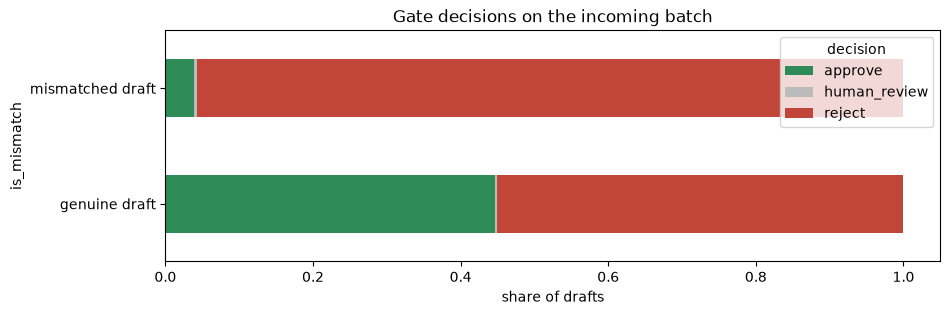

In [6]:
quality = batch_quality(out, out["is_mismatch"])
write_text(f"{batch_prefix}/quality.json", json.dumps(quality, indent=2))
print(json.dumps(quality, indent=2))

table = pd.crosstab(out["is_mismatch"].map({0: "genuine draft", 1: "mismatched draft"}), out["decision"],
                    normalize="index")
ax = table.plot.barh(stacked=True, color={"approve": "#2e8b57", "reject": "#c2453a", "human_review": "#bbb"},
                     figsize=(10, 3))
ax.set_title("Gate decisions on the incoming batch")
ax.set_xlabel("share of drafts")
plt.show()

In [7]:
print("Rejected mismatches (correctly caught):")
caught = out[(out["is_mismatch"] == 1) & (out["decision"] == "reject")]
caught[["app_id", "true_tags", "predicted_tags", "agreement"]].head(5)

Rejected mismatches (correctly caught):


,app_id,true_tags,predicted_tags,agreement
1,3673560,"[Singleplayer, Casual, 2D, Puzzle, Colorful, Pixel Graphics, Cute,...","[Singleplayer, Indie, Casual, Adventure, 2D, 3D, Atmospheric, Pixe...",0.4211
4,2292800,"[Singleplayer, Indie, Action, 3D, RPG]","[Singleplayer, Indie, Casual, 2D, Simulation, Strategy, Pixel Grap...",0.3077
12,3417350,"[Singleplayer, Indie, Casual, Adventure, 2D, Puzzle, Colorful, Cute]","[Singleplayer, Indie, Casual, 2D, Strategy, Pixel Graphics, Fantasy]",0.5333
14,3623140,"[Singleplayer, Casual, 2D, Strategy, Colorful, Cute]","[Singleplayer, Indie, Casual, Adventure, 3D, Simulation, Puzzle, A...",0.2353
15,3365970,"[Singleplayer, Indie, Casual, 2D, Strategy, Pixel Graphics, Cute, ...","[Singleplayer, Indie, Casual, 2D, Simulation, RPG, Story Rich]",0.5333


In [8]:
write_text(f"{layout.batch}/LATEST", batch_prefix)
print("Batch outputs for monitoring:", batch_prefix)

Batch outputs for monitoring: s3://sagemaker-us-east-1-326278567375/steam-store-copilot/batch/20261017-180846
